<div align="center">

**UNIVERSIDADE PRESBITERIANA MACKENZIE — Ciência de Dados EaD**

# PREVISÃO DE CRESCIMENTO E MENSURAÇÃO DO EFEITO DE SUBSTITUIÇÃO DO PIX SOBRE OS MEIOS DE PAGAMENTO CONCORRENTES NO BRASIL

**Projeto Aplicado IV — Entrega 3: Implementação Parcial (26/10/2026)**

Cainã Fernandes Guimarães da Silva · Gabriel de Oliveira Meloni · Humberto Guttau Bravo · Jimmy Paiva Gomes

</div>

---

## Sumário

1. Introdução
2. Motivações e justificativa
3. Referencial teórico
4. Objetivos
5. Pipeline da solução proposta
6. Coleta e inventário dos dados
7. Análise exploratória e pré-processamento
8. Modelo base: SARIMA e AutoARIMA
9. Cronograma atualizado
10. Próximos passos e referências

---

### Histórico de revisão (em relação à entrega anterior)

- **Entrega 2 (feedback do professor):** inclusão de citações no referencial teórico (seções 3.3 a 3.5); seleção de hiperparâmetros por AutoARIMA; apresentação do pipeline; linha de apresentação do cronograma; figuras e tabelas agora são introduzidas no texto antes de aparecerem.
- **Correções técnicas identificadas na revisão do notebook:**
  - A série do Pix derivada dos microdados não é comparável às estatísticas mensais do BCB (ver seção 7.2). Ela deixa de ser a série-alvo, e a série-alvo passa a ser a `MeiosdePagamentosMensalDA`, com dados deduplicados.
  - O ajuste do SARIMA na versão anterior usava a série sem normalização e, depois, a normalização Min-Max sobre todo o período. Agora a normalização é ajustada só no treino, para evitar vazamento de dados no teste.
  - A grade de candidatos anterior misturava termos sazonais com e sem diferenciação D=1. A busca agora é feita de forma consistente, com AutoARIMA.
  - Os números de decomposição sazonal citados em texto foram recalculados a partir da saída do código.
  - O modelo base SARIMA(0,1,0)(0,1,1)12 divergia na janela de treino porque o ajuste usava `enforce_invertibility=False` (coeficiente MA de −5,7e13). Com a invertibilidade imposta, o ajuste converge (seção 8.2). O MAPE de 1,52% que esse ajuste divergente produzia não é um resultado válido.
  - O teste de Ljung-Box agora descarta os 13 primeiros resíduos (d + D·s), que vêm da inicialização do filtro de Kalman e distorcem o teste.
  - A série trimestral de cartões estava corrompida: o CSV perdeu o trimestre original de cada linha e os totais caíam 95%. Ela foi reconstruída por diferença entre rótulos consecutivos e validada contra a Abecs (seção 7.3).
  - O índice trimestral antigo usava como base um trimestre com apenas 2 meses (4T20), o que inflava o crescimento inicial. Agora só entram trimestres completos.
  - A causa do artefato dos microdados do Pix foi confirmada pelo log de execução (seção 7.2): cada consulta devolve o mês pedido e os seguintes, e a agregação somou todas as respostas. As 728.009 primeiras linhas são uma cópia limpa da série.
  - O texto sobre o endpoint DOC foi corrigido: o DOC tem valores não nulos até o início de 2024, e não zero em todo o período.
  - Observações informais de rascunho foram removidas.

## 1 Introdução

O Pix, sistema de pagamentos instantâneos lançado pelo Banco Central do Brasil (BCB) em novembro de 2020, tornou-se em poucos anos um dos principais meios de pagamento eletrônico do país. Ele alterou a dinâmica de uso de instrumentos consolidados, como boletos bancários, cheques, transferências eletrônicas (TED/DOC) e cartões de crédito e débito. A literatura recente associa sua criação à digitalização dos pagamentos e a mudanças na estrutura competitiva do mercado financeiro (SCHAPIRO; MOUALLEM; DANTAS, 2023; FERREIRA, 2022).

O tema tem relevância além do meio acadêmico. Em 2025, o Escritório do Representante Comercial dos Estados Unidos (USTR) iniciou investigação sob a Seção 301 do Trade Act de 1974 que incluiu os serviços de pagamento eletrônico (USTR, 2025). A determinação publicada em 2026 questiona a atuação do Pix como iniciativa regulada e, ao mesmo tempo, operada pelo próprio Banco Central (USTR, 2026). No mercado, a Abecs informa que o setor de cartões movimentou R$ 4,5 trilhões em 2025, com crescimento de 10,1% frente a 2024 (CNN BRASIL, 2026). Esse dado sugere uma relação mais complexa do que a simples substituição.

**Problema de pesquisa:** em que medida o Pix substituiu cada um dos meios de pagamento concorrentes e em que medida os complementou, por meio da expansão da base de usuários bancarizados?

## 2 Motivações e justificativa

A literatura já documenta efeitos distintos do Pix sobre diferentes instrumentos. Sampaio e Ornelas (2024) encontram evidências de complementaridade entre o Pix e pagamentos com cartão. Balan, Klotzle e Norden (2026) associam o Pix à inclusão financeira e à substituição do uso de dinheiro em espécie. Essa evidência, porém, é em grande parte descritiva. Falta uma abordagem quantitativa e reprodutível que isole o efeito do Pix da tendência natural de cada série.

A análise exploratória da seção 7 sustenta essa motivação. Ela mostra que o ticket médio por transação Pix caiu de cerca de R$ 890 em novembro de 2020 para o mínimo de R$ 392 em fevereiro de 2024, e depois oscilou entre R$ 392 e R$ 480 até julho de 2026, na estatística mensal do BCB (seção 7.2). Essa trajetória é compatível com uma fase de incorporação de novos usuários e de casos de uso de menor valor, seguida de maturação do padrão de uso.

O método proposto combina previsão com SARIMA, contrafactuais com ARIMAX de intervenção, testes de causalidade de Granger e detecção de pontos de mudança. Ele não se restringe ao caso brasileiro e pode avaliar outras inovações de pagamento.

## 3 Referencial teórico

### 3.1 O arranjo Pix

O Pix foi instituído pela Resolução BCB nº 1, de 12 de agosto de 2020 (BANCO CENTRAL DO BRASIL, 2020a), e seus requisitos de remessa de informações foram definidos pela Instrução Normativa BCB nº 32 (BANCO CENTRAL DO BRASIL, 2020b). A liquidação em tempo real e a ausência de custo para o pagador distinguem o Pix de instrumentos como TED e boleto. Sampaio e Ornelas (2024) argumentam que essa diferença de tecnologia produz complementaridades com cartões, e não apenas substituição.

### 3.2 Meios de pagamento concorrentes

Os concorrentes considerados são boleto bancário, cheque, TED/DOC e cartões de crédito e débito. O DOC tem valores não nulos até o início de 2024 e depois zera, o que é consistente com sua descontinuação. Como consequência, ele é excluído da modelagem e mantido apenas no inventário.

### 3.3 Séries temporais, sazonalidade e estacionariedade

Uma série é estacionária quando sua média, sua variância e sua autocovariância não dependem do tempo. Séries com tendência ou sazonalidade precisam de diferenciação antes da modelagem. A diferenciação simples (d) remove a tendência, e a sazonal (D, com período s) remove o padrão que se repete a cada s observações (BOX; JENKINS, 1976). Testes formais complementam a inspeção visual. O teste Dickey-Fuller aumentado (ADF) tem como hipótese nula a presença de raiz unitária (DICKEY; FULLER, 1979). O teste KPSS tem como hipótese nula a estacionariedade (KWIATKOWSKI et al., 1992). Os dois são usados em conjunto porque suas hipóteses nulas são opostas.

### 3.4 Modelos SARIMA e seleção automática de hiperparâmetros

O modelo SARIMA(p,d,q)(P,D,Q)s combina componentes autorregressivos, de médias móveis e de diferenciação, tanto na parte regular quanto na sazonal (BOX; JENKINS, 1976). A escolha manual da ordem é subjetiva e costuma exigir muitas tentativas. O AutoARIMA automatiza essa escolha: testes de raiz unitária definem d e D, e a busca em p, q, P e Q minimiza um critério de informação, geralmente o AIC (HYNDMAN; KHANDAKAR, 2008). Neste projeto, a busca é feita com o pacote `pmdarima`, e seu resultado é comparado ao modelo base SARIMA(0,1,0)(0,1,1)12, escolhido por inspeção do correlograma e do AIC na versão anterior. O resíduo do modelo final é verificado com o teste de Ljung-Box (LJUNG; BOX, 1978).

### 3.5 Análise de intervenção, causalidade de Granger e pontos de mudança

A análise de intervenção estima o efeito de um evento sobre uma série por meio de um modelo ARIMA com variável exógena que representa o evento (BOX; TIAO, 1975). Essa é a base dos contrafactuais previstos no objetivo b. A causalidade de Granger testa se a história de uma série melhora a previsão de outra, o que não equivale a causalidade estrutural, mas permite avaliar a relação de precedência entre as séries (GRANGER, 1969). A detecção de pontos de mudança identifica instantes em que a distribuição da série muda de forma significativa. O método PELT, por exemplo, encontra a segmentação ótima com custo computacional linear (KILLICK et al., 2012).

## 4 Objetivos

**Objetivo geral:** modelar a trajetória de adoção do Pix e mensurar seu efeito sobre os principais meios de pagamento concorrentes no Brasil.

- **a)** Prever a série mensal de transações Pix com SARIMA, com ordem definida por AutoARIMA e comparada ao modelo base. *Status: modelo base ajustado e validado; AutoARIMA implementado nesta entrega.*
- **b)** Construir contrafactuais com ARIMAX de intervenção para cada instrumento concorrente. *Status: pendente, para a Entrega 4.*
- **c)** Confirmar o efeito por causalidade de Granger e detecção de pontos de mudança. *Status: pendente, para a Entrega 4.*

## 5 Pipeline da solução proposta

A solução é organizada em etapas sequenciais. Cada etapa recebe os artefatos da anterior e produz um arquivo verificável. O pipeline foi revisado nesta entrega: a série-alvo passou a vir das estatísticas mensais do BCB, e a etapa de comparação de fontes foi incluída antes da modelagem.

```mermaid
flowchart LR
    A[Coleta: API OData do BCB] --> B[Inventário e deduplicação]
    B --> C{Consistência entre fontes}
    C -->|Microdados divergem| D[Série-alvo: MeiosdePagamentosMensalDA]
    D --> E[Junção mensal e trimestral]
    E --> F[EDA: decomposição, ACF/PACF, ADF/KPSS]
    F --> G[Pré-processamento: Min-Max ajustado no treino]
    G --> H[Modelo base SARIMA e AutoARIMA]
    H --> I[Validação: métricas no teste e Ljung-Box]
    I --> J[Entrega 4: ARIMAX, Granger, change point]
```

## 6 Coleta e inventário dos dados

As fontes são públicas e vêm da API OData (Plataforma Olinda) do BCB, sem autenticação. A Tabela 1 resume as bases utilizadas.

**Tabela 1 — Fontes de dados.** Fonte: elaboração própria a partir das APIs do BCB.

| Endpoint | Granularidade e período | Uso neste projeto | Status |
|---|---|---|---|
| `EstatisticasTransacoesPix` | Mensal, nov/2020 a jul/2026 | Ticket médio e perfil de uso (microdados) | Coletado; o arquivo inteiro tem respostas sobrepostas, e só as 728.009 primeiras linhas são válidas (seção 7.2) |
| `MeiosdePagamentosMensalDA` | Mensal, nov/2020 a jul/2026 | **Série-alvo** e concorrentes mensais | Coletado; exige deduplicação |
| `Quantidadeetransacoesdecartoes` | Trimestral, 4T20 a 2T26 | Concorrentes (cartões) | Coletado; trimestre original perdido, **reconstruído** por diferença entre rótulos (seção 7.3); 2T26 fora da série |
| `MeiosdePagamentosTrimestralDA` | Trimestral | Não utilizado | Erro 500 no servidor do BCB em todos os trimestres testados |

**Sobre a coleta.** A coleta dos microdados do Pix foi interrompida manualmente no primeiro mês: cada mês tem cerca de 700 mil linhas, o que tornaria inviável manter tudo em memória. A célula de coleta é mantida apenas como registro e não deve ser reexecutada. As células abaixo leem os CSVs já gravados e só executam a coleta se a flag `RECOLETAR` for verdadeira. **As funções de coleta corrigidas não foram testadas contra a API nesta revisão** (sem acesso à rede). Ao rodá-las, confira que cada mês e cada trimestre aparece uma única vez.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pmdarima as pm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

RECOLETAR = False  # manter False: os dados já estão persistidos em CSV
print("pacotes carregados; RECOLETAR =", RECOLETAR)

pacotes carregados; RECOLETAR = False


In [2]:
import requests, time, os

BASE_MPV = "https://olinda.bcb.gov.br/olinda/servico/MPV_DadosAbertos/versao/v1/odata/"

def _get(endpoint, param, valor):
    url = f"{BASE_MPV}{endpoint}({param}=@{param})?@{param}='{valor}'&$format=json"
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    return pd.DataFrame(r.json().get("value", []))

def coletar_meios_mensal(caminho="meios_pagamento_mensal.csv"):
    # Uma consulta basta: a resposta traz o mês pedido e todos os seguintes (nos CSVs atuais,
    # 2.415 linhas = 69 x 70 / 2). Repetir a consulta mês a mês só gera linhas repetidas.
    df = _get("MeiosdePagamentosMensalDA", "AnoMes", "202011")
    df = df.drop_duplicates(subset="AnoMes").sort_values("AnoMes")
    df.to_csv(caminho, index=False)
    return df

def coletar_cartoes(caminho="cartoes_trimestral.csv"):
    # Idem. IMPORTANTE: não sobrescrever o trimestre devolvido pela API com o parâmetro da consulta,
    # que foi o que corrompeu o CSV anterior. Se o parâmetro for guardado, usar outro nome de coluna.
    df = _get("Quantidadeetransacoesdecartoes", "trimestre", "20204")
    df = df.drop_duplicates()
    df.to_csv(caminho, index=False)
    return df

if RECOLETAR:
    coletar_meios_mensal()
    coletar_cartoes()
    print("coleta concluída; conferir que há 1 linha por mês e 1 conjunto de linhas por trimestre")
else:
    print("coleta desabilitada: lendo CSVs persistidos")

coleta desabilitada: lendo CSVs persistidos


## 7 Análise exploratória e pré-processamento

### 7.1 Inventário e qualidade dos dados

A primeira verificação é quantitativa. Para cada base, conferimos o número de linhas, a presença de duplicatas, a cobertura temporal e valores ausentes. A Tabela 2 resume o resultado.

In [3]:
meios_bruto = pd.read_csv("meios_pagamento_mensal.csv")
pix_bruto = pd.read_csv("pix_serie_mensal.csv")
cartoes_bruto = pd.read_csv("cartoes_trimestral.csv")

def resumo(df, nome, chave):
    return {
        "base": nome,
        "linhas_brutas": len(df),
        "linhas_unicas_chave": df[chave].nunique(),
        "duplicadas": len(df) - len(df.drop_duplicates()),
        "ausentes_total": int(df.isna().sum().sum()),
    }

inventario = pd.DataFrame([
    resumo(meios_bruto, "MeiosdePagamentosMensalDA", "AnoMes"),
    resumo(pix_bruto, "pix_serie_mensal (microdados agregados)", "AnoMes"),
    resumo(cartoes_bruto, "Quantidadeetransacoesdecartoes", "trimestre"),
])
print("Tabela 2 — Inventário das bases")
inventario

Tabela 2 — Inventário das bases


,base,linhas_brutas,linhas_unicas_chave,duplicadas,ausentes_total
0,MeiosdePagamentosMensalDA,2415,69,2346,0
1,pix_serie_mensal (microdados agregados),69,69,0,0
2,Quantidadeetransacoesdecartoes,31867,23,69,0


A base `MeiosdePagamentosMensalDA` tem 2.415 linhas para 69 meses. Isso significa que cada mês aparece, em média, 35 vezes, e o total é exatamente 69 × 70 / 2. A causa é a forma como a API responde: a consulta por mês devolve a série a partir daquele mês, e a gravação de cada resposta acrescentou linhas repetidas. As linhas repetidas são idênticas (a deduplicação completa e a por `AnoMes` dão o mesmo resultado). A deduplicação por `AnoMes` remove essas repetições e recupera a série de 69 meses. Os dados deduplicados são usados a partir daqui.

O DOC tem valores não nulos até o início de 2024. Esse ponto difere da versão anterior, que afirmava valor zero em todo o período. Por isso o DOC é retirado da modelagem por descontinuação, mas a série permanece no inventário.

In [4]:
meios = (meios_bruto.drop_duplicates(subset="AnoMes")
         .sort_values("AnoMes").reset_index(drop=True))
meios["data"] = pd.to_datetime(meios["AnoMes"].astype(str), format="%Y%m")

# Verificação de cobertura: meses consecutivos sem lacunas
meses_esperados = pd.date_range(meios["data"].min(), meios["data"].max(), freq="MS")
print("Meses esperados:", len(meses_esperados), "| Meses presentes:", meios["data"].nunique())
print("Lacunas:", set(meses_esperados) - set(meios["data"]))

doc_por_ano = meios.assign(ano=meios["data"].dt.year).groupby("ano")["quantidadeDOC"].sum()
print("\nQuantidade de DOC por ano (mil):")
print(doc_por_ano)

Meses esperados: 69 | Meses presentes: 69
Lacunas: set()

Quantidade de DOC por ano (mil):
ano
2020    39,137.74
2021   104,731.55
2022    59,019.09
2023    35,137.67
2024       662.65
2025         0.00
2026         0.00
Name: quantidadeDOC, dtype: float64


### 7.2 Consistência entre fontes

Antes de escolher a série-alvo, comparamos a série agregada dos microdados do Pix com a estatística mensal do BCB para o próprio Pix. As duas deveriam medir a mesma coisa. A razão entre elas é calculada abaixo.

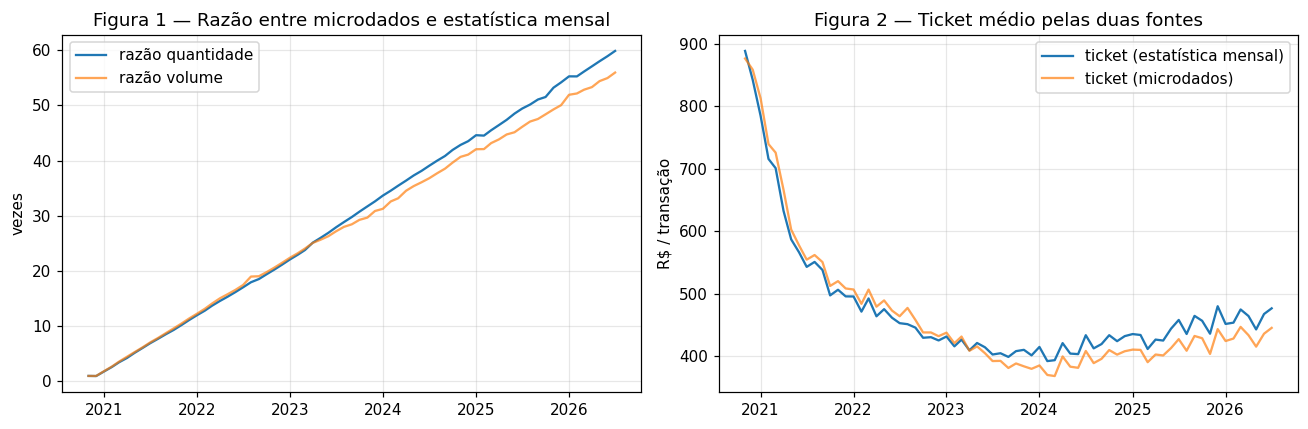

         data  razao_qtd  razao_vol
0  2020-11-01       0.90       0.89
12 2021-11-01      10.13      10.40
24 2022-11-01      20.21      20.56
36 2023-11-01      31.67      29.64
48 2024-11-01      42.84      40.67
60 2025-11-01      53.23      49.28
68 2026-07-01      59.90      55.97


In [5]:
pix_micro = pix_bruto.sort_values("AnoMes").reset_index(drop=True)
pix_micro["data"] = pd.to_datetime(pix_micro["AnoMes"].astype(str), format="%Y%m")

comparacao = meios[["data", "quantidadePix", "valorPix"]].merge(
    pix_micro[["data", "qtd_total", "volume_total"]], on="data", how="inner")

# Unidades inferidas: quantidade em mil transações e valor em R$ milhões (a confirmar nos metadados do BCB)
comparacao["razao_qtd"] = comparacao["qtd_total"] / (comparacao["quantidadePix"] * 1e3)
comparacao["razao_vol"] = comparacao["volume_total"] / (comparacao["valorPix"] * 1e6)
comparacao["ticket_meios"] = (comparacao["valorPix"] * 1e6) / (comparacao["quantidadePix"] * 1e3)
comparacao["ticket_micro"] = comparacao["volume_total"] / comparacao["qtd_total"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(comparacao["data"], comparacao["razao_qtd"], label="razão quantidade")
ax[0].plot(comparacao["data"], comparacao["razao_vol"], label="razão volume", alpha=0.7)
ax[0].set_title("Figura 1 — Razão entre microdados e estatística mensal")
ax[0].set_ylabel("vezes"); ax[0].legend()
ax[1].plot(comparacao["data"], comparacao["ticket_meios"], label="ticket (estatística mensal)")
ax[1].plot(comparacao["data"], comparacao["ticket_micro"], label="ticket (microdados)", alpha=0.7)
ax[1].set_title("Figura 2 — Ticket médio pelas duas fontes"); ax[1].set_ylabel("R$ / transação"); ax[1].legend()
plt.tight_layout(); plt.show()

print(comparacao[["data", "razao_qtd", "razao_vol"]].iloc[[0, 12, 24, 36, 48, 60, 68]])

In [6]:
k = np.arange(len(comparacao))
comparacao["razao_por_consulta"] = comparacao["razao_qtd"] / (k + 1)
print("Razão (microdados / estatística mensal) dividida por (k + 1), k = índice do mês:")
print(comparacao.set_index("data")["razao_por_consulta"].iloc[[0, 12, 24, 36, 48, 60, 68]].round(2).to_string())

Razão (microdados / estatística mensal) dividida por (k + 1), k = índice do mês:
data
2020-11-01   0.90
2021-11-01   0.78
2022-11-01   0.81
2023-11-01   0.86
2024-11-01   0.87
2025-11-01   0.87
2026-07-01   0.87


A Figura 1 mostra que a razão entre as duas fontes não é constante: fica perto de 1 em novembro de 2020 e chega a cerca de 60 em julho de 2026. A causa é de coleta, e o log de execução a confirma. A API devolve, a cada consulta, o mês pedido e todos os seguintes, e a agregação somou todas as respostas. No arquivo de microdados (28.354.037 linhas), a multiplicidade de cada mês é um número inteiro exato, tanto em linhas quanto em quantidade, e cresce de 1 (nov/2020) até 66 (jul/2026). Ela repete o valor do mês anterior em três meses (dez/2020, fev/2025 e fev/2026), o que é compatível com três consultas que falharam, como a de dezembro de 2020 registrada na coleta original. As 728.009 primeiras linhas, que correspondem à primeira consulta, contêm exatamente uma cópia de cada um dos 69 meses. A célula acima mostra a razão dividida por k + 1, que deixa de crescer.

A Figura 2 mostra que o ticket médio pelas duas fontes tem a mesma forma. Esse resultado é esperado: numerador e denominador do ticket são multiplicados pelo mesmo fator, que então se cancela. A estatística mensal cai de R$ 888 (nov/2020) para R$ 410 (nov/2023), atinge o mínimo de R$ 392 em fev/2024 e sobe para R$ 477 em jul/2026.

Portanto, a quantidade agregada sobre o arquivo inteiro não é válida, mas a série calculada só com a primeira consulta é. Ela fica entre 83% e 91% da estatística mensal do BCB, sobe lentamente de 0,83 (2021) para 0,91 (2026) e varia 1,09 vez entre o maior e o menor valor. Essa diferença de 9% a 17% ainda não tem explicação, e pode vir de definição de transação ou de unidade. Ela é registrada como limitação. Por isso a série-alvo continua sendo `quantidadePix` de `MeiosdePagamentosMensalDA`, na mesma fonte e na mesma escala dos concorrentes.

**Correção:** os microdados não precisam ser recoletados. Basta usar as 728.009 primeiras linhas, o que também reduz o arquivo (próxima subseção).

#### Redução do arquivo de microdados

O arquivo `pix_microdados.csv` ocupa 1,43 GB e tem 28.354.037 linhas, das quais só 728.009 (2,6%) são a série correta. A função abaixo lê essas primeiras linhas, **valida** o recorte contra a estatística mensal e só então grava uma versão compacta. Ela não apaga o arquivo original.

A validação exige 69 meses distintos e uma razão estável entre a quantidade dos microdados e a da estatística mensal (variação máxima de 1,5 vez entre o maior e o menor valor). No log de execução, o recorte atende às duas condições: os 69 meses aparecem com multiplicidade exatamente 1 e a variação da razão é de 1,09 vez. Não se deve usar `drop_duplicates()` no arquivo inteiro: como o `$select` descartou 5 das 10 dimensões, linhas legítimas podem ficar idênticas nas colunas restantes.

A gravação do arquivo reduzido ainda não foi executada no ambiente do autor. O arquivo de 1,43 GB deve ficar no `.gitignore`, pois o GitHub rejeita arquivos acima de 100 MB.

In [7]:
REDUZIR_MICRODADOS = True  # exige pix_microdados.csv na pasta; é ignorado se o arquivo não existir

def reduzir_microdados(caminho="pix_microdados.csv", n_linhas=728_009,
                       destino="pix_microdados.parquet", tolerancia=1.5):
    cols = ["AnoMes", "PAG_PFPJ", "REC_PFPJ", "PAG_IDADE", "FINALIDADE", "VALOR", "QUANTIDADE"]
    df = pd.read_csv(caminho, nrows=n_linhas, usecols=cols)

    n_meses = df["AnoMes"].nunique()
    serie_micro = df.groupby("AnoMes")["QUANTIDADE"].sum().sort_index()
    ref = meios.set_index("AnoMes")["quantidadePix"].sort_index() * 1e3
    razao = (serie_micro / ref).dropna()
    variacao = razao.max() / razao.min()

    print(f"Linhas lidas: {len(df):,} | meses distintos: {n_meses}")
    print(f"Razão micro/mensal: mín {razao.min():.2f}, máx {razao.max():.2f}, variação {variacao:.2f}x")

    if n_meses != 69 or variacao >= tolerancia:
        print("VALIDAÇÃO FALHOU: o recorte não parece ser a série correta. Nada foi gravado. Recolete os dados.")
        return None

    try:
        df.to_parquet(destino, compression="zstd", index=False)
    except ImportError:
        destino = destino.replace(".parquet", ".csv.gz")
        df.to_csv(destino, index=False, compression="gzip")

    antes = os.path.getsize(caminho) / 1e6
    depois = os.path.getsize(destino) / 1e6
    print(f"Validação OK. {antes:,.0f} MB -> {depois:,.0f} MB ({destino}), redução de {antes / depois:,.0f}x")
    return df

if REDUZIR_MICRODADOS and os.path.exists("pix_microdados.csv"):
    micro = reduzir_microdados()
else:
    print("Redução não executada (REDUZIR_MICRODADOS = False ou arquivo ausente).")

Linhas lidas: 728,009 | meses distintos: 69
Razão micro/mensal: mín 0.83, máx 0.91, variação 1.09x
Validação OK. 1,431 MB -> 8 MB (pix_microdados.parquet), redução de 174x


### 7.3 Seleção da série-alvo e junção das bases

A série-alvo e os concorrentes mensais formam um painel indexado por mês. Para comparar o crescimento relativo dos instrumentos, os meses são somados em trimestres. Entram só trimestres completos: o primeiro da série (4T20) tem 2 meses e o último (3T26) tem 1, e ambos distorceriam o índice. Os cartões, que já são trimestrais, são reconstruídos antes da junção.

In [8]:
painel = meios[["data", "quantidadePix", "valorPix", "quantidadeTED",
                "quantidadeCheque", "quantidadeBoleto"]].copy()
painel = painel.rename(columns={
    "quantidadePix": "pix_qtd_mil", "valorPix": "pix_valor_mi",
    "quantidadeTED": "ted_qtd_mil", "quantidadeCheque": "cheque_qtd_mil",
    "quantidadeBoleto": "boleto_qtd_mil"}).set_index("data")

painel["trimestre"] = painel.index.year * 10 + (painel.index.month - 1) // 3 + 1
meses_por_tri = painel.groupby("trimestre").size()
tri_completos = meses_por_tri[meses_por_tri == 3].index
print("Meses por trimestre nas pontas:", meses_por_tri.iloc[[0, 1, -1]].to_dict())

trim = (painel[painel["trimestre"].isin(tri_completos)]
        .groupby("trimestre")[["pix_qtd_mil", "ted_qtd_mil", "cheque_qtd_mil", "boleto_qtd_mil"]].sum())
print(f"Trimestres completos do painel mensal: {trim.index[0]} a {trim.index[-1]} ({len(trim)})")

Meses por trimestre nas pontas: {20204: 2, 20211: 3, 20263: 1}
Trimestres completos do painel mensal: 20211 a 20262 (22)


#### Cartões: diagnóstico e reconstrução

O CSV de cartões não pode ser usado como está. O diagnóstico está na Tabela 3.

In [9]:
diag = cartoes_bruto.groupby("trimestre").agg(
    linhas=("trimestre", "size"),
    transacoes_bi=("qtdTransacoesNacionais", lambda s: s.sum() / 1e9))
diag["diferenca_para_proximo_bi"] = diag["transacoes_bi"] - diag["transacoes_bi"].shift(-1)
print("Tabela 3 — Cartões: linhas e transações nacionais por rótulo de trimestre")
diag.round(1)

Tabela 3 — Cartões: linhas e transações nacionais por rótulo de trimestre


,linhas,transacoes_bi,diferenca_para_proximo_bi
trimestre,,,
20204,2685,216.90,6.50
20211,2571,210.40,6.00
20212,2458,204.40,6.50
20213,2343,197.90,7.60
20214,2229,190.30,8.50
20221,2112,181.80,8.30
20222,1996,173.50,8.90
20223,1880,164.60,9.30
20224,1761,155.40,9.90


Na Tabela 3, o número de linhas por rótulo cai de 2.685 (4T20) para 130 (1T26 e 2T26), e o total de transações nacionais cai de cerca de 217 bilhões para cerca de 12 bilhões, uma queda de 95%. Isso contradiz o crescimento do setor (CNN BRASIL, 2026). A causa é a mesma dos microdados: cada consulta devolveu o trimestre pedido e os seguintes, e o código gravou o parâmetro da consulta na coluna `trimestre`, sobrescrevendo o trimestre real de cada linha.

Como as linhas repetidas são idênticas, o trimestre t pode ser recuperado pela diferença entre o conjunto de linhas do rótulo t e o do rótulo t + 1. A função abaixo faz isso por contagem de linhas idênticas e verifica que o rótulo seguinte está contido no anterior. O rótulo 20262 não está contido em 20261 (os dois compartilham apenas 1 das 130 linhas), e o total de 20262, de 11,8 bilhões, é praticamente igual ao do 2T25 (11,9 bilhões), em contraste com o crescimento de 5,5% a/a do 1T26. Por isso o 2T26 fica fora da série até ser confirmado.

In [10]:
def reconstruir_cartoes(df):
    # Cada rótulo t contém as linhas dos trimestres t, t+1, ... (cópias idênticas).
    # Trimestre t = linhas do rótulo t menos as linhas do rótulo t+1, contadas como multiconjunto.
    cols = [c for c in df.columns if c != "trimestre"]
    d = df.assign(_h=pd.util.hash_pandas_object(df[cols], index=False).values)
    rot = sorted(d["trimestre"].unique())
    cont = {t: d[d["trimestre"] == t].groupby("_h").size() for t in rot}
    quarto, fora = {}, []
    for k, a in enumerate(rot):
        prox = rot[k + 1] if k + 1 < len(rot) else None
        aninhado = prox is not None and bool((cont[prox] <= cont[a].reindex(cont[prox].index).fillna(0)).all())
        quarto[a] = cont[a].sub(cont[prox], fill_value=0) if aninhado else cont[a]
        if not aninhado:
            fora = [int(t) for t in rot[k + 1:]]   # rótulos fora da cadeia: não usados
            break
    partes = []
    for a, dif in quarto.items():
        base_a = d[d["trimestre"] == a].drop_duplicates("_h").set_index("_h")
        dif = dif[dif > 0]
        linhas = base_a.loc[np.repeat(dif.index.values, dif.values.astype(int))].copy()
        linhas["trimestre"] = int(a)
        partes.append(linhas.reset_index(drop=True))
    return pd.concat(partes, ignore_index=True), fora

cartoes_rec, fora_da_cadeia = reconstruir_cartoes(cartoes_bruto)
linhas_tri = cartoes_rec.groupby("trimestre").size()
print(f"Trimestres reconstruídos: {linhas_tri.size} ({linhas_tri.index.min()} a {linhas_tri.index.max()}) | "
      f"linhas por trimestre: mín {linhas_tri.min()}, máx {linhas_tri.max()}")
print("Rótulos fora da cadeia (não usados):", fora_da_cadeia)

cart_trim = cartoes_rec.groupby(["trimestre", "nomeFuncao"])["qtdTransacoesNacionais"].sum().unstack()
cart_valor = cartoes_rec.groupby(["trimestre", "nomeFuncao"])["valorTransacoesNacionais"].sum().unstack()
ano_valor = cart_valor.groupby(cart_valor.index // 10).sum()
cresc_valor = ano_valor.loc[2025] / ano_valor.loc[2024] - 1
print("\nValidação externa: crescimento do valor nacional em 2025 sobre 2024")
print(cresc_valor.round(3).to_string())
print("total:", round(float(ano_valor.loc[2025].sum() / ano_valor.loc[2024].sum() - 1), 3),
      "| valor de 2025 (R$ tri):", round(float(ano_valor.loc[2025].sum() / 1e12), 2))

Trimestres reconstruídos: 22 (20204 a 20261) | linhas por trimestre: mín 113, máx 132
Rótulos fora da cadeia (não usados): [20262]

Validação externa: crescimento do valor nacional em 2025 sobre 2024
nomeFuncao
Crédito     0.15
Débito     -0.02
Pré-Pago    0.12
total: 0.107 | valor de 2025 (R$ tri): 4.34


A reconstrução é validada por uma fonte externa. Nos trimestres reconstruídos, o valor de transações nacionais de 2025 sobre 2024 cresce 15,1% no crédito e 10,7% no total, e soma R$ 4,34 trilhões. A Abecs informa crescimento de 14,5% no crédito e de 10,1% no total, com R$ 4,5 trilhões (CNN BRASIL, 2026). A diferença residual é esperada, porque o CSV traz só transações nacionais. A série reconstruída, portanto, é consistente com a fonte setorial, e os cartões entram na junção.

In [11]:
cart_idx = cart_trim.rename(columns={"Crédito": "cartao_credito_qtd", "Débito": "cartao_debito_qtd",
                                     "Pré-Pago": "cartao_prepago_qtd"})
trim_all = trim.join(cart_idx, how="left")   # 2T26 fica sem cartões (NaN)
indice = trim_all / trim_all.iloc[0] * 100
print(f"Trimestres: {trim_all.index[0]} a {trim_all.index[-1]} ({len(trim_all)}); base 100 = {trim_all.index[0]}")
print("Tabela 4 — Índice base 100 por trimestre (1T21 = 100)")
indice.round(1)

Trimestres: 20211 a 20262 (22); base 100 = 20211
Tabela 4 — Índice base 100 por trimestre (1T21 = 100)


,pix_qtd_mil,ted_qtd_mil,cheque_qtd_mil,boleto_qtd_mil,cartao_credito_qtd,cartao_debito_qtd,cartao_prepago_qtd
trimestre,,,,,,,
20211,100.00,100.00,100.00,100.00,100.00,100.00,100.00
20212,217.00,93.80,95.20,104.20,110.00,104.50,143.60
20213,332.00,84.40,94.60,108.30,128.10,117.30,194.00
20214,444.90,83.80,92.50,108.50,144.70,128.10,245.40
20221,492.80,73.20,83.80,105.60,142.40,119.50,260.00
20222,631.70,72.60,82.40,107.30,153.80,125.70,303.30
20223,757.10,73.10,82.00,108.90,160.70,127.50,339.40
20224,905.30,72.50,75.50,107.50,167.80,137.00,394.50
20231,941.20,65.20,69.50,106.80,162.20,127.60,389.90


A Tabela 4 mostra o crescimento relativo, com base 100 no 1T21 (primeiro trimestre completo). A comparação é por índice, e não por valores absolutos, porque as séries têm escalas muito diferentes. Os cartões vão até o 1T26.

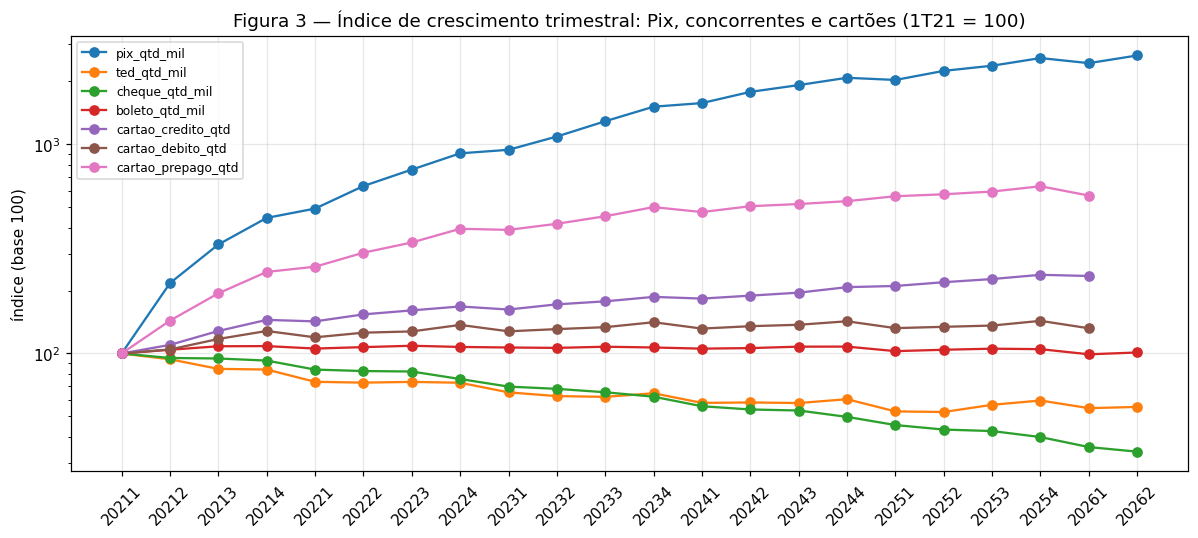

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
for col in indice.columns:
    ax.plot(indice.index.astype(str), indice[col], marker="o", label=col)
ax.set_title("Figura 3 — Índice de crescimento trimestral: Pix, concorrentes e cartões (1T21 = 100)")
ax.set_ylabel("índice (base 100)"); ax.set_yscale("log"); ax.legend(fontsize=8); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

A Figura 3 usa escala logarítmica para que todas as séries caibam no mesmo gráfico. De 1T21 a 2T26, o Pix chega a cerca de 27 vezes o nível inicial. No mesmo período, a TED cai para cerca de 55% e o cheque para cerca de 34%, enquanto o boleto fica praticamente estável (índice entre 99 e 109). Entre os cartões (de 1T21 a 1T26), o crédito sobe para 235, o pré-pago para 569 e o débito fica em 132, no mesmo nível do 1T24 (132) e do 1T25 (132). Isso é uma descrição, e não uma estimativa de efeito causal. Ela sugere relações heterogêneas: queda de TED e cheque, estabilidade do boleto, expansão do crédito e do pré-pago e estagnação do débito. Essa é a hipótese a testar na Entrega 4.

### 7.4 Transformações e normalização

A série de quantidade do Pix cresce cerca de dez vezes entre 2020 e 2026. Essa magnitude torna a otimização numérica instável, como observado na versão anterior do notebook, que apresentava erro-padrão de `sigma2` da ordem de 1e-15. A solução adotada é a normalização Min-Max para [0, 1], em substituição à divisão por um fator fixo (1 milhão), que era uma solução arbitrária.

Para evitar vazamento de dados, o escalonador é ajustado **somente no treino**, na etapa de modelagem da seção 8. Na análise exploratória, a escala original é mantida, porque a decomposição e os testes de estacionariedade dependem da forma da série.

### 7.5 Decomposição sazonal e estacionariedade

A série de quantidade mensal do Pix é decomposta de forma multiplicativa, porque a amplitude da sazonalidade cresce com o nível da série. A decomposição aditiva da versão anterior produzia resíduos grandes em dezembro e fevereiro, que eram artefato da escolha de modelo e não anomalias reais. A decomposição multiplicativa é apresentada na Figura 4.

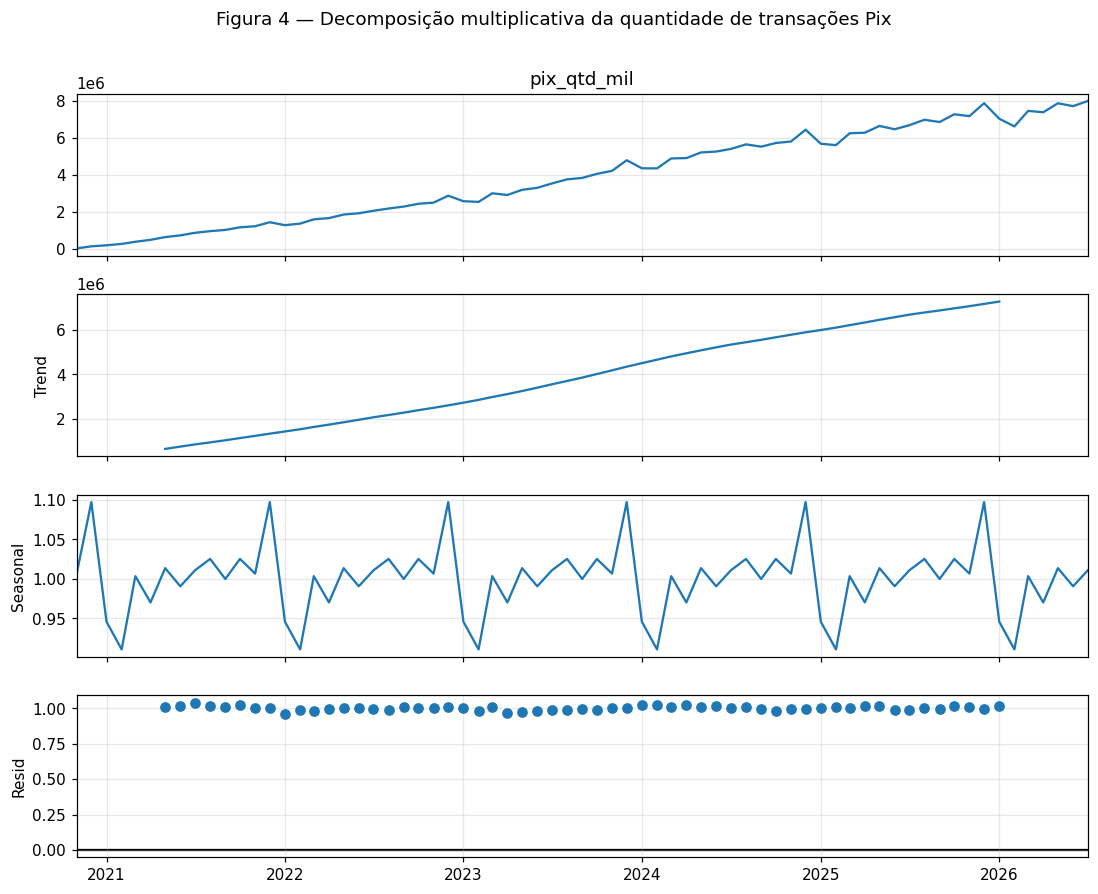

Fator sazonal médio por mês (1 = nível da tendência):
data
1    0.95
2    0.91
3    1.00
4    0.97
5    1.01
6    0.99
7    1.01
8    1.02
9    1.00
10   1.02
11   1.01
12   1.10
Name: seasonal, dtype: float64


In [13]:
serie_pix = painel["pix_qtd_mil"].asfreq("MS")
decomp = seasonal_decompose(serie_pix, model="multiplicative", period=12)

fig = decomp.plot()
fig.set_size_inches(10, 8)
plt.suptitle("Figura 4 — Decomposição multiplicativa da quantidade de transações Pix", y=1.01)
plt.tight_layout(); plt.show()

sazonal_medio = decomp.seasonal.groupby(decomp.seasonal.index.month).mean()
print("Fator sazonal médio por mês (1 = nível da tendência):")
print(sazonal_medio.round(3))

A Figura 4 separa a série em tendência, sazonalidade e resíduo. O fator sazonal médio é máximo em dezembro (1,10) e mínimo em fevereiro (0,91). A leitura dos valores é feita por comparação: um fator acima de 1 indica um mês acima da tendência, e abaixo de 1 indica um mês abaixo. A sazonalidade anual justifica o uso de componente sazonal de período 12, e não de um ARIMA simples.

In [14]:
def teste_estacionariedade(serie, nome):
    s = serie.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    return {"serie": nome,
            "ADF_p": round(adf_p, 4), "ADF_estacionaria": adf_p < 0.05,
            "KPSS_p": round(kpss_p, 4), "KPSS_estacionaria": kpss_p > 0.05}

testes = pd.DataFrame([
    teste_estacionariedade(serie_pix, "nível (y)"),
    teste_estacionariedade(serie_pix.diff(), "d = 1"),
    teste_estacionariedade(serie_pix.diff(12), "D = 1 (s = 12)"),
    teste_estacionariedade(serie_pix.diff().diff(12), "d = 1 e D = 1"),
])
print("Tabela 5 — Testes de estacionariedade (ADF: H0 = raiz unitária; KPSS: H0 = estacionária)")
testes

Tabela 5 — Testes de estacionariedade (ADF: H0 = raiz unitária; KPSS: H0 = estacionária)


,serie,ADF_p,ADF_estacionaria,KPSS_p,KPSS_estacionaria
0,nível (y),0.99,False,0.01,False
1,d = 1,0.56,False,0.05,True
2,D = 1 (s = 12),0.61,False,0.10,True
3,d = 1 e D = 1,0.00,True,0.10,True


In [15]:
# Sugestão de ordem de diferenciação pelos testes automáticos do pmdarima
d_sug = pm.arima.ndiffs(serie_pix, test="adf")
D_sug = pm.arima.nsdiffs(serie_pix, m=12, test="ocsb")
print(f"ndiffs (ADF) sugere d = {d_sug}; nsdiffs (OCSB) sugere D = {D_sug}")

ndiffs (ADF) sugere d = 1; nsdiffs (OCSB) sugere D = 1


A Tabela 5 mostra que a série em nível não é estacionária. Isoladamente, nem d = 1 nem D = 1 tornam a série estacionária (ADF p = 0,56 e p = 0,61). A combinação dos dois é aceita pelos testes ADF e KPSS. Os valores de `ndiffs` e `nsdiffs` impressos acima confirmam d = 1 e D = 1.

### 7.6 Autocorrelação para identificação da ordem

Com a série diferenciada (d = 1, D = 1), o correlograma ACF e o PACF indicam quais defasagens são significativas. A Figura 5 mostra essas funções para 24 defasagens.

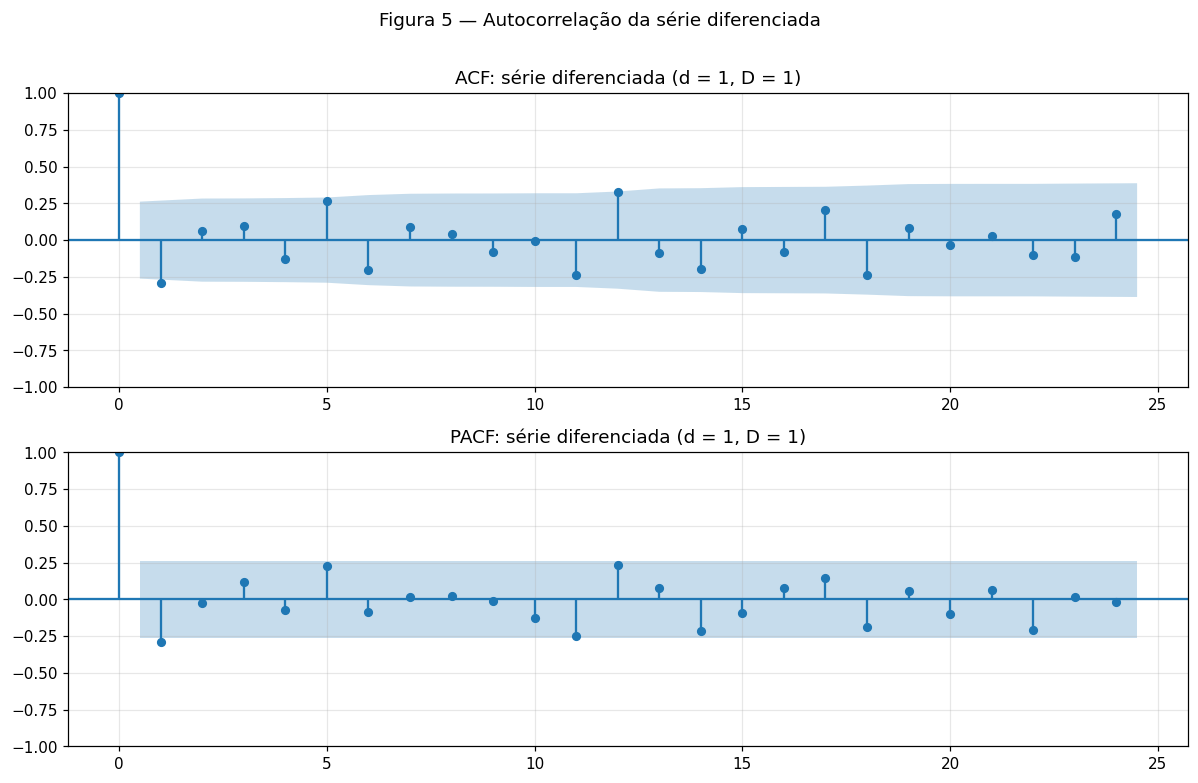

In [16]:
serie_dif = serie_pix.diff().diff(12).dropna()

fig, axs = plt.subplots(2, 1, figsize=(11, 7))
plot_acf(serie_dif, lags=24, ax=axs[0]); axs[0].set_title("ACF: série diferenciada (d = 1, D = 1)")
plot_pacf(serie_dif, lags=24, ax=axs[1], method="ywm"); axs[1].set_title("PACF: série diferenciada (d = 1, D = 1)")
plt.suptitle("Figura 5 — Autocorrelação da série diferenciada", y=1.01)
plt.tight_layout(); plt.show()

Na Figura 5, as defasagens sazonais de ordem 12 e as defasagens simples de ordem baixa são os candidatos naturais para os termos de média móvel e autorregressivos. Como a leitura do correlograma é subjetiva, a seleção final é feita pelo AutoARIMA na seção 8.

## 8 Modelo base: SARIMA e AutoARIMA

### 8.1 Divisão treino e teste

A série é dividida no tempo, sem embaralhamento. Os últimos 12 meses (agosto de 2025 a julho de 2026) formam o conjunto de teste. Assim, a avaliação mede a capacidade de previsão em meses que o modelo não viu, o que é a medida relevante para a previsão de adoção.

In [17]:
H = 12  # horizonte de teste, em meses
y = painel["pix_qtd_mil"].asfreq("MS")
y_tr, y_te = y.iloc[:-H], y.iloc[-H:]
print(f"Treino: {y_tr.index.min():%Y-%m} a {y_tr.index.max():%Y-%m} ({len(y_tr)} meses)")
print(f"Teste : {y_te.index.min():%Y-%m} a {y_te.index.max():%Y-%m} ({len(y_te)} meses)")

# Normalização ajustada SOMENTE no treino
scaler = MinMaxScaler().fit(y_tr.values.reshape(-1, 1))
tr_s = pd.Series(scaler.transform(y_tr.values.reshape(-1, 1)).ravel(), index=y_tr.index)
te_s = pd.Series(scaler.transform(y_te.values.reshape(-1, 1)).ravel(), index=y_te.index)

Treino: 2020-11 a 2025-07 (57 meses)
Teste : 2025-08 a 2026-07 (12 meses)


### 8.2 Modelo base: SARIMA(0,1,0)(0,1,1)12

O modelo base usa a especificação da versão anterior e é ajustado no treino normalizado. A versão anterior usava `enforce_invertibility=False`, e com essa opção o otimizador divergiu nesta janela de treino: o coeficiente de média móvel sazonal foi para cerca de −5,7e13, com `sigma2` próximo de zero e sem convergência. Esse ajuste degenerado produzia um MAPE de 1,52% que não tem valor. Com a invertibilidade imposta, o ajuste converge. Se o otimizador padrão não convergir, o ajuste é refeito com o método de Powell, partindo da solução anterior. A previsão é desfeita da normalização para comparação na escala original.

In [18]:
mod_base = sm.tsa.SARIMAX(tr_s, order=(0, 1, 0), seasonal_order=(0, 1, 1, 12),
                      enforce_stationarity=False, enforce_invertibility=True)
base = mod_base.fit(disp=False, maxiter=500)
if not base.mle_retvals.get("converged"):
    # reajuste com outro otimizador, partindo da solução anterior
    base = mod_base.fit(disp=False, method="powell", maxiter=2000, start_params=base.params)
print("Convergiu:", base.mle_retvals.get("converged"), "| AIC:", round(base.aic, 2))
print(base.summary().tables[1])

prev_base_s = base.get_forecast(H).predicted_mean.values
prev_base = scaler.inverse_transform(prev_base_s.reshape(-1, 1)).ravel()

Convergiu: True | AIC: -158.34
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L12       0.3472      0.295      1.178      0.239      -0.230       0.925
sigma2         0.0003      0.000      2.678      0.007    8.31e-05       0.001


### 8.3 AutoARIMA

O AutoARIMA busca a ordem (p,d,q)(P,D,Q)s que minimiza o AIC. Os limites de busca são pequenos porque a série tem 57 meses de treino. Os valores de d e D são definidos pelos testes padrão do `pmdarima` (KPSS para d e OCSB para D), que concordam com a seção 7.5. Nesta janela de treino, a busca escolhe SARIMA(0,1,0)(1,1,1)12, com AIC de −237,4 no ambiente do autor (statsmodels 0.14.6). O termo autorregressivo sazonal é significativo (p = 0,001), e o de média móvel sazonal não (p = 0,37). Os valores exatos variam um pouco entre versões das bibliotecas, mas a ordem escolhida é a mesma.

In [19]:
auto = pm.auto_arima(
    tr_s.values, m=12, seasonal=True,
    start_p=0, max_p=3, start_q=0, max_q=3,
    start_P=0, max_P=2, start_Q=0, max_Q=2,
    information_criterion="aic", stepwise=True,
    suppress_warnings=True, error_action="ignore", trace=False,
)
print("Ordem escolhida:", auto.order, "x", auto.seasonal_order)
print("AIC:", round(auto.aic(), 2))
print(auto.summary().tables[1])

prev_auto_s = auto.predict(n_periods=H)
prev_auto = scaler.inverse_transform(np.asarray(prev_auto_s).reshape(-1, 1)).ravel()

Ordem escolhida: (0, 1, 0) x (1, 1, 1, 12)
AIC: -237.4
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.S.L12       0.9456      0.288      3.288      0.001       0.382       1.509
ma.S.L12      -0.7107      0.789     -0.901      0.368      -2.257       0.836
sigma2         0.0002   7.83e-05      2.462      0.014    3.93e-05       0.000


### 8.4 Métricas e diagnóstico

Comparamos os dois modelos no teste, na escala original, com MAPE, RMSE e MAE. Também verificamos a autocorrelação dos resíduos pelo teste de Ljung-Box, em que a hipótese nula é ausência de autocorrelação. Um resíduo sem autocorrelação indica que o modelo captura a estrutura da série. Os 13 primeiros resíduos (d + D·s) são descartados no teste, porque vêm da inicialização do modelo.

In [20]:
def metricas(real, previsto):
    real, previsto = np.asarray(real), np.asarray(previsto)
    return {
        "MAPE (%)": np.mean(np.abs((real - previsto) / real)) * 100,
        "RMSE (mil)": np.sqrt(mean_squared_error(real, previsto)),
        "MAE (mil)": mean_absolute_error(real, previsto),
    }

tabela_metricas = pd.DataFrame({
    "SARIMA base": metricas(y_te.values, prev_base),
    "AutoARIMA": metricas(y_te.values, prev_auto),
}).T
print("Tabela 6 — Desempenho no conjunto de teste (escala original)")
tabela_metricas

Tabela 6 — Desempenho no conjunto de teste (escala original)


,MAPE (%),RMSE (mil),MAE (mil)
SARIMA base,2.42,"206,799.39","179,783.18"
AutoARIMA,1.38,"123,743.52","99,893.21"


In [21]:
burn = 1 + 12  # d + D*s: os primeiros resíduos vêm da inicialização do filtro e distorcem o teste
res_base = base.resid.iloc[burn:]
res_auto = pd.Series(auto.arima_res_.resid).iloc[burn:]

lb_base = acorr_ljungbox(res_base, lags=[12, 24], return_df=True)
print("Ljung-Box, SARIMA base:"); print(lb_base)
if res_auto is not None:
    lb_auto = acorr_ljungbox(res_auto, lags=[12, 24], return_df=True)
    print("\nLjung-Box, AutoARIMA:"); print(lb_auto)

Ljung-Box, SARIMA base:
    lb_stat  lb_pvalue
12     9.32       0.68
24    32.87       0.11

Ljung-Box, AutoARIMA:
    lb_stat  lb_pvalue
12     7.89       0.79
24    25.95       0.36


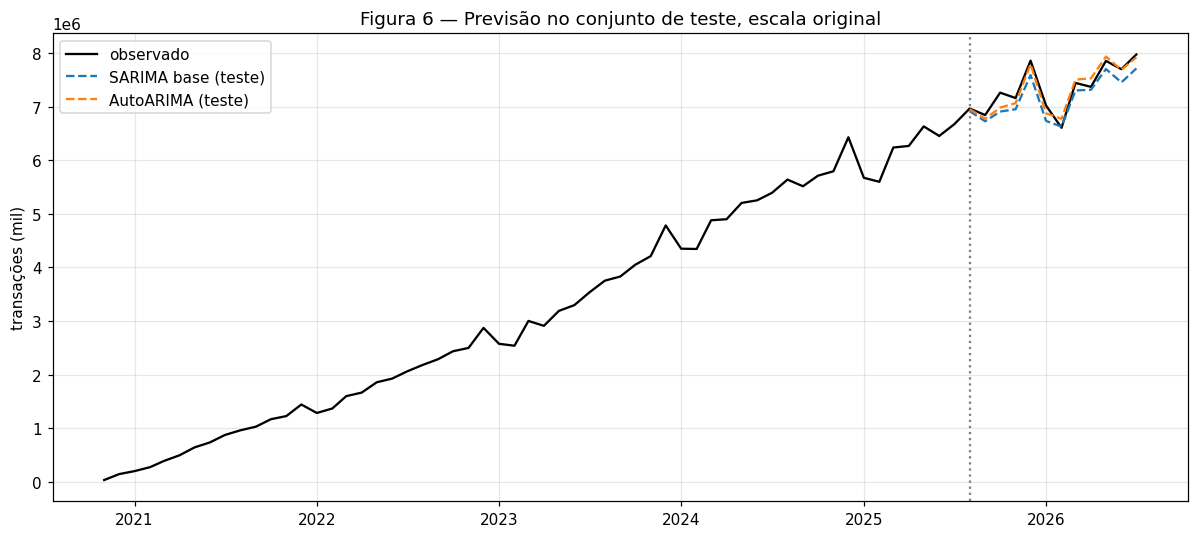

In [22]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(y.index, y.values, color="black", label="observado")
ax.plot(y_te.index, prev_base, "--", label="SARIMA base (teste)")
ax.plot(y_te.index, prev_auto, "--", label="AutoARIMA (teste)")
ax.axvline(y_te.index.min(), color="gray", linestyle=":")
ax.set_title("Figura 6 — Previsão no conjunto de teste, escala original")
ax.set_ylabel("transações (mil)"); ax.legend(); plt.tight_layout(); plt.show()

A Figura 6 compara as previsões com os valores observados nos 12 meses de teste. O AutoARIMA tem o menor erro: MAPE de 1,38% contra 2,42% do modelo base, RMSE de 124 mil contra 207 mil e AIC de −237,4 contra −158,3 (ver Tabela 6 e as saídas acima). Descartados os 13 primeiros resíduos, o teste de Ljung-Box não rejeita a ausência de autocorrelação em nenhum dos dois modelos. O AutoARIMA é adotado como modelo de referência para a Entrega 4. O coeficiente autorregressivo sazonal fica próximo de 1 (0,95), o que torna o ajuste sensível ao otimizador: em outro ambiente de execução, o mesmo modelo deu MAPE de 1,54%. A vantagem sobre o modelo base se mantém nos dois casos. Os testes têm poucos graus de liberdade com apenas 57 meses de treino, e o diagnóstico deve ser repetido no modelo final.

## 9 Cronograma atualizado

A Tabela 7 mostra o estado das atividades. A linha de apresentação do cronograma foi incluída como marco, conforme o feedback da Entrega 2.

**Tabela 7 — Cronograma atualizado.** Fonte: elaboração própria, a partir das datas das etapas no Gantt da entrega anterior.

| Etapa | Período (Gantt) | Atividades | Status |
|---|---|---|---|
| 1. Concepção e organização | até 01/09/2026 | Grupo e tema, bases da API do BCB, repositório, documentação inicial | Concluída |
| 1 | marco | **Apresentação do cronograma** | Linha incluída nesta versão |
| 2. Técnicas de investigação | 01/09 a 28/09/2026 | Componentes da série, pipeline analítico, referencial teórico | Concluída (referencial revisado nesta entrega) |
| 3. Implementação parcial | 29/09 a 26/10/2026 | Pré-processamento, modelo base e AutoARIMA, pipeline atualizado | Entrega atual |
| 4. Análise crítica e entrega final | 27/10 a 30/11/2026 | **Validar a razão dos microdados e o 2T26 de cartões** (seções 7.2 e 7.3) | Pendente, prioridade |
| 4 | idem | ARIMAX de intervenção, Granger, pontos de mudança | Pendente |
| 4 | idem | Análise crítica, produto e artefatos finais | Pendente |

*As datas por atividade dentro de cada etapa devem ser transpostas do Gantt aprovado. Aqui constam só as datas das etapas.*

## 10 Próximos passos e referências

**Próximos passos.** (1) Investigar a razão de 0,83 a 0,91 entre os microdados e a estatística mensal e a origem das três consultas que falharam. (2) Confirmar o 2T26 de cartões, cujo rótulo (20262) está fora da cadeia. (3) Gerar contrafactuais com ARIMAX de intervenção para cada concorrente, incluindo agora os cartões. (4) Aplicar causalidade de Granger e detecção de pontos de mudança. (5) Repetir o diagnóstico de resíduos no modelo final.

### Referências

BALAN, Philipe; KLOTZLE, Marcelo Cabus; NORDEN, Lars. Fast payment systems and deposit dynamics: evidence from Brazil's Pix. SSRN, 2026. Disponível em: https://doi.org/10.2139/ssrn.6415438.

BANCO CENTRAL DO BRASIL. Resolução BCB nº 1, de 12 de agosto de 2020. Institui o arranjo de pagamentos Pix. Brasília, DF: BCB, 2020a.

BANCO CENTRAL DO BRASIL. Instrução Normativa BCB nº 32, de 26 de outubro de 2020. Brasília, DF: BCB, 2020b.

BANCO CENTRAL DO BRASIL. Portal de Dados Abertos: Estatísticas do Pix. Brasília, DF: BCB, [2026]. Disponível em: https://dadosabertos.bcb.gov.br/dataset/pix.

BANCO CENTRAL DO BRASIL. Portal de Dados Abertos: Estatísticas de Meios de Pagamento. Brasília, DF: BCB, [2026]. Disponível em: https://dadosabertos.bcb.gov.br/dataset/estatisticas-meios-pagamentos.

BOX, George E. P.; JENKINS, Gwilym M. Time Series Analysis: Forecasting and Control. San Francisco: Holden-Day, 1976.

BOX, George E. P.; TIAO, George C. Intervention analysis with applications to economic and environmental problems. Journal of the American Statistical Association, v. 70, n. 349, p. 70–79, 1975.

CNN BRASIL. Setor de cartões movimenta R$ 4,5 tri em 2025, mostra Abecs. São Paulo, 11 fev. 2026.

DICKEY, David A.; FULLER, Wayne A. Distribution of the estimators for autoregressive time series with a unit root. Journal of the American Statistical Association, v. 74, n. 366, p. 427–431, 1979.

FERREIRA, Alexandre Rebêlo. Arranjo Pix: regulação e concorrência em pagamentos digitais. Revista da Procuradoria-Geral do Banco Central, v. 16, n. 1, p. 100–113, 2022. DOI: https://doi.org/10.58766/rpgbcb.v16i1.1158.

GRANGER, Clive W. J. Investigating causal relations by econometric models and cross-spectral methods. Econometrica, v. 37, n. 3, p. 424–438, 1969.

HYNDMAN, Rob J.; KHANDAKAR, Yeasmin. Automatic time series forecasting: the forecast package for R. Journal of Statistical Software, v. 27, n. 3, 2008.

KILLICK, Rebecca; FEARNHEAD, Paul; ECKLEY, Idris A. Optimal detection of changepoints with a linear computational cost. Journal of the American Statistical Association, v. 107, n. 500, p. 1590–1598, 2012.

KWIATKOWSKI, Denis; PHILLIPS, Peter C. B.; SCHMIDT, Peter; SHIN, Yongcheol. Testing the null hypothesis of stationarity against the alternative of a unit root. Journal of Econometrics, v. 54, p. 159–178, 1992.

LJUNG, Greta M.; BOX, George E. P. On a measure of lack of fit in time series models. Biometrika, v. 65, n. 2, p. 297–303, 1978.

SAMPAIO, Matheus C.; ORNELAS, José Renato Haas. Payment technology complementarities and their consequences in the banking sector: evidence from Brazil's Pix. Banco Central do Brasil, Working Paper Series, n. 600, 2024.

SCHAPIRO, Mario G.; MOUALLEM, Pedro Salomon Bezerra; DANTAS, Eric Gil. PIX: explaining a state-owned Fintech. Brazilian Journal of Political Economy, v. 43, n. 4, p. 874–892, 2023. DOI: https://doi.org/10.1590/0101-31572023-3470.

UNITED STATES TRADE REPRESENTATIVE (USTR). Initiation of Section 301 Investigation: Brazil's Acts, Policies, and Practices Related to Digital Trade and Electronic Payment Services. Federal Register, 18 jul. 2025.

UNITED STATES TRADE REPRESENTATIVE (USTR). Notice of Determination and Request for Comments Concerning Action Pursuant to Section 301. Federal Register, 4 jun. 2026.

*Nota: as referências de Box e Jenkins, Dickey e Fuller, Kwiatkowski et al., Granger, Hyndman e Khandakar, Killick et al., Ljung e Box, e Box e Tiao foram incluídas a partir de conhecimento da área e devem ser conferidas na fonte original antes da entrega.*

## 11 Log de execução (para diagnóstico)

A célula abaixo gera o arquivo `log_execucao.txt`, um resumo compacto de tudo que o notebook produziu: ambiente, inventário dos arquivos, diagnósticos de qualidade, tabelas intermediárias, parâmetros e métricas dos modelos e, se o arquivo existir, estatísticas dos microdados lidos em blocos (sem carregar o arquivo inteiro na memória). O objetivo é permitir a revisão dos resultados sem precisar enviar os arquivos grandes. **Rode o notebook inteiro e envie apenas o `log_execucao.txt`.** O arquivo contém totais e amostras de poucas linhas, não os dados completos.

In [23]:
import io, sys, platform, datetime, traceback
import sklearn, matplotlib

LOG_LER_MICRODADOS = True      # leitura em blocos do pix_microdados.csv (pode levar alguns minutos)
CAMINHO_LOG = "log_execucao.txt"
_buf = io.StringIO()

def w(*args):
    print(*args, file=_buf)

def secao(titulo, fn):
    w("\n" + "=" * 78); w(titulo); w("=" * 78)
    try:
        fn()
    except Exception as e:
        w(f"[ERRO nesta seção: {type(e).__name__}: {e}]")
        w(traceback.format_exc(limit=3))

def s_ambiente():
    w("data/hora:", datetime.datetime.now().isoformat(timespec="seconds"))
    w("python:", sys.version.split()[0], "|", platform.platform())
    for m in (pd, np, sm, pm, sklearn, matplotlib):
        w(f"{m.__name__}: {getattr(m, '__version__', '?')}")
    w("flags: RECOLETAR =", RECOLETAR, "| REDUZIR_MICRODADOS =", REDUZIR_MICRODADOS,
      "| LOG_LER_MICRODADOS =", LOG_LER_MICRODADOS)
    w("\narquivos na pasta de trabalho:")
    for f in sorted(os.listdir(".")):
        if os.path.isfile(f):
            w(f"  {f:45s} {os.path.getsize(f) / 1e6:12.2f} MB")

def s_arquivos():
    for f in sorted(os.listdir(".")):
        if not f.endswith(".csv") or f == "pix_microdados.csv":
            continue
        if os.path.getsize(f) > 300e6:
            w(f"\n--- {f}: pulado (> 300 MB)"); continue
        d = pd.read_csv(f)
        w(f"\n--- {f}: {d.shape[0]:,} linhas x {d.shape[1]} colunas")
        w("colunas/dtypes:", dict(d.dtypes.astype(str)))
        w("nulos por coluna:", {k: int(v) for k, v in d.isna().sum().items() if v} or "nenhum")
        w("linhas duplicadas exatas:", int(d.duplicated().sum()))
        w("head(3):\n" + d.head(3).to_string())
        w("tail(3):\n" + d.tail(3).to_string())

def s_meios_e_comparacao():
    cont = meios_bruto.groupby("AnoMes").size()
    w("linhas brutas:", len(meios_bruto), "| meses distintos:", cont.size)
    w("repetições por mês: mín", int(cont.min()), "máx", int(cont.max()), "média", round(float(cont.mean()), 2))
    w("contagens = 1, 2, ..., 69 (padrão 'do mês em diante')?", sorted(cont.tolist()) == list(range(1, cont.size + 1)))
    w("DOC (mil) por ano:\n" + doc_por_ano.to_string())
    w("\ncomparação microdados x estatística mensal (todos os meses):")
    cols = ["data", "quantidadePix", "qtd_total", "razao_qtd", "razao_vol", "razao_por_consulta",
            "ticket_meios", "ticket_micro"]
    w(comparacao[cols].to_string(index=False))

def s_cartoes():
    w("diagnóstico por rótulo de trimestre (Tabela 3):\n" + diag.round(2).to_string())
    k = ["nomeBandeira", "nomeFuncao", "produto", "modalidade"]
    w("\ncombinações distintas de (bandeira, função, produto, modalidade) por rótulo:")
    w(cartoes_bruto.groupby("trimestre")[k].apply(lambda g: len(g.drop_duplicates())).to_string())
    w("\ntransações nacionais por rótulo e função (bi):")
    w((cartoes_bruto.groupby(["trimestre", "nomeFuncao"])["qtdTransacoesNacionais"].sum().unstack() / 1e9).round(2).to_string())
    w("\nreconstrução: rótulos fora da cadeia:", fora_da_cadeia)
    w("linhas por trimestre reconstruído:\n" + linhas_tri.to_string())
    w("\ntransações nacionais reconstruídas por trimestre e função (bi):\n" + (cart_trim / 1e9).round(3).to_string())
    w("\ncrescimento do valor nacional 2025/2024:\n" + cresc_valor.round(4).to_string())

def s_painel():
    w("meses por trimestre nas pontas:", meses_por_tri.iloc[[0, 1, -1]].to_dict())
    w("\ntrimestres completos (soma, mil):\n" + trim.round(0).to_string())
    w("\níndice base 100 (Tabela 4):\n" + indice.round(1).to_string())

def s_eda():
    w("fator sazonal médio por mês:\n" + sazonal_medio.round(4).to_string())
    w("\ntestes de estacionariedade (Tabela 5):\n" + testes.to_string(index=False))
    w(f"\nndiffs (ADF) = {d_sug} | nsdiffs (OCSB) = {D_sug}")
    w("\nresíduo da decomposição multiplicativa (describe):\n" + decomp.resid.dropna().describe().round(4).to_string())

def s_modelos():
    w(f"treino: {y_tr.index.min():%Y-%m} a {y_tr.index.max():%Y-%m} ({len(y_tr)}) | teste: {y_te.index.min():%Y-%m} a {y_te.index.max():%Y-%m} ({len(y_te)})")
    w(f"escalonador: min = {scaler.data_min_[0]:.2f} | max = {scaler.data_max_[0]:.2f} (treino)")
    w(f"\nSARIMA base (0,1,0)(0,1,1,12): convergiu = {base.mle_retvals.get('converged')} | AIC = {base.aic:.2f} | BIC = {base.bic:.2f}")
    w("parâmetros:", {k: float(v) for k, v in base.params.items()})
    w("otimizador (retvals):", {k: v for k, v in base.mle_retvals.items() if isinstance(v, (int, float, bool, str))})
    w("p-valores:", {k: round(float(v), 4) for k, v in base.pvalues.items()})
    w(f"\nAutoARIMA: ordem = {auto.order} x {auto.seasonal_order} | AIC = {auto.aic():.2f}")
    ra = auto.arima_res_
    w("parâmetros:", dict(zip(ra.param_names, [float(v) for v in ra.params])))
    w("p-valores:", dict(zip(ra.param_names, [round(float(v), 4) for v in ra.pvalues])))
    w("\nmétricas no teste (Tabela 6):\n" + tabela_metricas.round(2).to_string())
    w("\nLjung-Box, base (sem os 13 primeiros resíduos):\n" + lb_base.round(4).to_string())
    w("\nLjung-Box, AutoARIMA:\n" + lb_auto.round(4).to_string())
    comp = pd.DataFrame({"observado": y_te.values, "previsto_base": prev_base, "previsto_auto": prev_auto}, index=y_te.index)
    comp["erro_pct_base"] = (comp["previsto_base"] / comp["observado"] - 1) * 100
    comp["erro_pct_auto"] = (comp["previsto_auto"] / comp["observado"] - 1) * 100
    w("\nprevisto x observado no teste (mil transações):\n" + comp.round(2).to_string())

def s_microdados(caminho="pix_microdados.csv", n_primeira=728_009, bloco=500_000):
    if not LOG_LER_MICRODADOS:
        w("leitura desabilitada (LOG_LER_MICRODADOS = False)"); return
    if not os.path.exists(caminho):
        w("pix_microdados.csv não encontrado na pasta de trabalho"); return
    w(f"tamanho: {os.path.getsize(caminho) / 1e9:.3f} GB | n_primeira (linhas da 1ª consulta) = {n_primeira:,}")
    tot = None; prim = None
    visto = 0; ant = None; n_sobe = 0; n_desce = 0; sobe_pos = []; blocos = []
    for ch in pd.read_csv(caminho, usecols=["AnoMes", "VALOR", "QUANTIDADE"], chunksize=bloco):
        a = ch["AnoMes"].to_numpy()
        prev = np.concatenate([[a[0] if ant is None else ant], a[:-1]])
        sobe = np.flatnonzero(a > prev)
        n_sobe += len(sobe); n_desce += int((a < prev).sum())
        for p in sobe:
            if len(sobe_pos) < 300:
                sobe_pos.append((visto + int(p), int(prev[p]), int(a[p])))
        g = ch.groupby("AnoMes").agg(linhas=("QUANTIDADE", "size"), qtd=("QUANTIDADE", "sum"), valor=("VALOR", "sum"))
        tot = g if tot is None else tot.add(g, fill_value=0)
        corte = max(0, n_primeira - visto)
        if corte > 0:
            g1 = ch.iloc[:corte].groupby("AnoMes").agg(linhas=("QUANTIDADE", "size"), qtd=("QUANTIDADE", "sum"), valor=("VALOR", "sum"))
            prim = g1 if prim is None else prim.add(g1, fill_value=0)
        blocos.append((visto, len(ch), int(a.min()), int(a.max()), int(ch["AnoMes"].nunique())))
        visto += len(ch); ant = a[-1]
    w(f"linhas totais: {visto:,} | meses distintos: {len(tot)}")
    w(f"transições de AnoMes entre linhas consecutivas: subidas = {n_sobe:,} | descidas = {n_desce:,}")
    w("primeiras posições onde AnoMes sobe (posição, anterior, novo), até 300:\n" + str(sobe_pos))
    w("\nblocos de leitura (início, linhas, AnoMes mín, AnoMes máx, meses distintos):")
    w(pd.DataFrame(blocos, columns=["inicio", "linhas", "min", "max", "meses"]).to_string(index=False))
    res = pd.DataFrame({"linhas_total": tot["linhas"], "linhas_1a_consulta": prim["linhas"],
                        "qtd_total": tot["qtd"], "qtd_1a_consulta": prim["qtd"]})
    res["multiplicidade_linhas"] = res["linhas_total"] / res["linhas_1a_consulta"]
    res["multiplicidade_qtd"] = res["qtd_total"] / res["qtd_1a_consulta"]
    w("\npor AnoMes (total do arquivo x primeiras n_primeira linhas):\n" + res.round(3).to_string())
    # comparação com a estatística mensal
    ref = meios.set_index("AnoMes")["quantidadePix"].sort_index() * 1e3
    cmp_ = pd.DataFrame({"razao_total": res["qtd_total"] / ref, "razao_1a_consulta": res["qtd_1a_consulta"] / ref}).dropna()
    w("\nrazão microdados / estatística mensal:\n" + cmp_.round(3).to_string())
    w(f"\nvariação máx/mín da razão (1ª consulta): {cmp_['razao_1a_consulta'].max() / cmp_['razao_1a_consulta'].min():.3f}")

secao("1. AMBIENTE", s_ambiente)
secao("2. ARQUIVOS CSV (exceto microdados)", s_arquivos)
secao("3. MEIOS DE PAGAMENTO MENSAL E COMPARAÇÃO COM MICRODADOS", s_meios_e_comparacao)
secao("4. CARTÕES", s_cartoes)
secao("5. PAINEL E ÍNDICE TRIMESTRAL", s_painel)
secao("6. ANÁLISE EXPLORATÓRIA", s_eda)
secao("7. MODELAGEM", s_modelos)
secao("8. MICRODADOS DO PIX (leitura em blocos)", s_microdados)

texto = _buf.getvalue()
with open(CAMINHO_LOG, "w", encoding="utf-8") as f:
    f.write(texto)
print(f"Log gravado em {CAMINHO_LOG}: {len(texto) / 1e3:.1f} KB, {texto.count(chr(10)):,} linhas")
print("Envie esse arquivo para revisão. Trecho inicial:\n")
print(texto[:1500])

Log gravado em log_execucao.txt: 50.1 KB, 686 linhas
Envie esse arquivo para revisão. Trecho inicial:


1. AMBIENTE
data/hora: 2026-10-23T18:43:58
python: 3.11.9 | Windows-10-10.0.19045-SP0
pandas: 2.2.3
numpy: 2.2.6
statsmodels.api: 0.14.6
pmdarima: 2.1.1
sklearn: 1.6.0
matplotlib: 3.10.0
flags: RECOLETAR = False | REDUZIR_MICRODADOS = True | LOG_LER_MICRODADOS = True

arquivos na pasta de trabalho:
  .gitattributes                                        0.00 MB
  Projeto Aplicado IV.docx                              0.51 MB
  Projeto Aplicado IV.pdf                               0.62 MB
  Proposta_Projeto_Pix.docx                             0.01 MB
  README.md                                             0.00 MB
  analise_exploratoria_entrega3.ipynb                   0.62 MB
  cartoes_trimestral.csv                                2.98 MB
  concorrentes_cartoes_exploratoria.png                 0.10 MB
  concorrentes_mensal_exploratoria.png                  0.22 MB
  log_execucao.txt  